# Netflix Content Analysis & ML Project

**Project Type:** Exploratory Data Analysis + Classification  
**Goal:** Understand Netflix content and build a simple machine-learning model to predict whether a title is a **Movie** or **TV Show**.

**Name:pavan patil

## 1. Project Summary
In this project we analyze a Netflix titles dataset to discover patterns in content type, release year, ratings, countries, genres, and duration. We clean missing and duplicate values, create useful features, visualize important relationships, perform basic hypothesis testing, and build classification models.

**Workflow:** Business Question → Data Understanding → Cleaning → EDA → Feature Engineering → Hypothesis Testing → ML → Evaluation → Business Insights → Future Work

1**Business Question & Problem Framing:** Defining our analytical goals and outlining strategic business values.
2. **Data Ingestion & Understanding:** Loading raw files and performing structural assessments on data columns and shapes.
3. **Data Preprocessing & Cleaning:** Resolving structural data errors, string trimming, duplicate records removal, and filling categorical voids.
4. **Exploratory Data Analysis (EDA):** Deep-dive data visualization using Seaborn and Matplotlib to look into content distribution patterns, maturity ratings, and user scoring metrics.
5. **Advanced Feature Engineering:** 
   - Extracting structural title lengths and word counts.
   - Using NLP via Text Tokenization and **TF-IDF (Term Frequency-Inverse Document Frequency)** vectorization with unigram and bigram ranges.
6. **Dimensionality Reduction:** Compressing high-dimensional text feature matrices using **Truncated SVD (Singular Value Decomposition)**.
7. **Unsupervised Machine Learning (Clustering):** Optimizing model settings using the Silhouette Score Elbow method and training an advanced **K-Means Clustering** algorithm.
8. **Cluster Profiling & Evaluation:** Analyzing cluster silhouettes, evaluating cluster metrics (Davies-Bouldin, Calinski-Harabasz), and summarizing distinct semantic group personas.
9. **Strategic Business Insights:** Formulating data-driven conclusions for metadata management and system enhancements.

## 2. Problem Statement
Netflix has a large and diverse catalog of movies and TV shows. A useful analytics system should help identify content patterns and understand what characteristics distinguish movies from TV shows.

**Main question:** Can available metadata such as release year, rating, and duration predict whether a Netflix title is a Movie or a TV Show?

**Business value:** The analysis can support catalog planning, content strategy, recommendation systems, and metadata quality checks.

## 3. Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt     # libraries imported
import seaborn as sns


In [3]:
from sklearn.preprocessing import StandardScaler ,OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.metrics import(silhouette_score,calinski_harabasz_score,davies_bouldin_score)
pd.set_option("display.max_columns",None)
sns.set_theme(style="whitegrid")

## 4. Load the Dataset

In [4]:
df =pd .read_csv("netflix.csv")#load file .csv

In [5]:
print("Shape:",df.shape)


Shape: (1000, 7)


## 5. First Data Check

In [6]:
display(df.head)

<bound method NDFrame.head of                        title rating  \
0               White Chicks  PG-13   
1        Lucky Number Slevin      R   
2             Grey's Anatomy  TV-14   
3               Prison Break  TV-14   
4      How I Met Your Mother  TV-PG   
..                       ...    ...   
995                  The BFG     PG   
996  The Secret Life of Pets     PG   
997         Precious Puppies   TV-G   
998              Beary Tales   TV-G   
999          Growing Up Wild      G   

                                           ratinglevel  ratingdescription  \
0    crude and sexual humor, language and some drug...                 80   
1    strong violence, sexual content and adult lang...                100   
2    Parents strongly cautioned. May be unsuitable ...                 90   
3    Parents strongly cautioned. May be unsuitable ...                 90   
4    Parental guidance suggested. May not be suitab...                 70   
..                                     

## 6. Data Information, Duplicates and Missing Values

In [7]:
display(df.info)


<bound method DataFrame.info of                        title rating  \
0               White Chicks  PG-13   
1        Lucky Number Slevin      R   
2             Grey's Anatomy  TV-14   
3               Prison Break  TV-14   
4      How I Met Your Mother  TV-PG   
..                       ...    ...   
995                  The BFG     PG   
996  The Secret Life of Pets     PG   
997         Precious Puppies   TV-G   
998              Beary Tales   TV-G   
999          Growing Up Wild      G   

                                           ratinglevel  ratingdescription  \
0    crude and sexual humor, language and some drug...                 80   
1    strong violence, sexual content and adult lang...                100   
2    Parents strongly cautioned. May be unsuitable ...                 90   
3    Parents strongly cautioned. May be unsuitable ...                 90   
4    Parental guidance suggested. May not be suitab...                 70   
..                                   

In [8]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
title,1000,496,13 Reasons Why,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rating,1000,13,TV-14,234,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ratinglevel,941,99,Parents strongly cautioned. May be unsuitable ...,224,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ratingdescription,1000.0,NaN,NaN,NaN,67.366,30.78561,10.0,35.0,60.0,90.0,124.0
release_year,1000.0,NaN,NaN,NaN,2010.335,8.877927,1940.0,2007.0,2015.0,2016.0,2017.0
user_rating_score,605.0,NaN,NaN,NaN,84.094215,12.344371,55.0,75.0,88.0,95.0,99.0
user_rating_size,1000.0,NaN,NaN,NaN,80.783,0.973066,80.0,80.0,80.0,82.0,82.0


data checks

In [9]:
print("missing values:")
print(df.isna().sum())# shows missing valus

missing values:
title                  0
rating                 0
ratinglevel           59
ratingdescription      0
release_year           0
user_rating_score    395
user_rating_size       0
dtype: int64


In [10]:
print("\nDuplicate rows :", df.duplicated().sum())


Duplicate rows : 500


In [11]:
print("\n Data type:" )
print(df.dtypes)


 Data type:
title                 object
rating                object
ratinglevel           object
ratingdescription      int64
release_year           int64
user_rating_score    float64
user_rating_size       int64
dtype: object


In [12]:
print("\n unique rating:")
print(df["rating"].value_counts(dropna=False))


 unique rating:
rating
TV-14       234
PG          170
TV-MA       148
G           138
TV-Y         68
TV-PG        59
TV-G         52
TV-Y7-FV     44
TV-Y7        38
R            19
PG-13        15
NR           14
UR            1
Name: count, dtype: int64


In [13]:
print("\nRelease-year range:")
print(df ["release_year"].min(),"to",df["release_year"].max())


Release-year range:
1940 to 2017


clean data

In [14]:
#kip cop of the raw data
raw_df =df.copy()

In [15]:
raw_df

,title,rating,ratinglevel,ratingdescription,release_year,user_rating_score,user_rating_size
0,White Chicks,PG-13,"crude and sexual humor, language and some drug...",80,2004,82.0,80
1,Lucky Number Slevin,R,"strong violence, sexual content and adult lang...",100,2006,NaN,82
2,Grey's Anatomy,TV-14,Parents strongly cautioned. May be unsuitable ...,90,2016,98.0,80
3,Prison Break,TV-14,Parents strongly cautioned. May be unsuitable ...,90,2008,98.0,80
4,How I Met Your Mother,TV-PG,Parental guidance suggested. May not be suitab...,70,2014,94.0,80
...,...,...,...,...,...,...,...
995,The BFG,PG,"for action/peril, some scary moments and brief...",60,2016,97.0,80
996,The Secret Life of Pets,PG,for action and some rude humor,60,2016,NaN,81
997,Precious Puppies,TV-G,Suitable for all ages.,35,2003,NaN,82
998,Beary Tales,TV-G,Suitable for all ages.,35,2013,NaN,82


In [16]:
#remove duplicate rows 
df=df.drop_duplicates().copy()

In [17]:
df.copy()

,title,rating,ratinglevel,ratingdescription,release_year,user_rating_score,user_rating_size
0,White Chicks,PG-13,"crude and sexual humor, language and some drug...",80,2004,82.0,80
1,Lucky Number Slevin,R,"strong violence, sexual content and adult lang...",100,2006,NaN,82
2,Grey's Anatomy,TV-14,Parents strongly cautioned. May be unsuitable ...,90,2016,98.0,80
3,Prison Break,TV-14,Parents strongly cautioned. May be unsuitable ...,90,2008,98.0,80
4,How I Met Your Mother,TV-PG,Parental guidance suggested. May not be suitab...,70,2014,94.0,80
...,...,...,...,...,...,...,...
989,Russell Madness,PG,some rude humor and sports action,60,2015,NaN,82
993,Wiener Dog Internationals,G,General Audiences. Suitable for all ages.,35,2015,NaN,82
994,Pup Star,G,General Audiences. Suitable for all ages.,35,2016,NaN,82
997,Precious Puppies,TV-G,Suitable for all ages.,35,2003,NaN,82


In [18]:
# before filling create missingness flag
df["user_rating_missing"] = df["user_rating_score"].isna().astype(int)

In [19]:
df

,title,rating,ratinglevel,ratingdescription,release_year,user_rating_score,user_rating_size,user_rating_missing
0,White Chicks,PG-13,"crude and sexual humor, language and some drug...",80,2004,82.0,80,0
1,Lucky Number Slevin,R,"strong violence, sexual content and adult lang...",100,2006,NaN,82,1
2,Grey's Anatomy,TV-14,Parents strongly cautioned. May be unsuitable ...,90,2016,98.0,80,0
3,Prison Break,TV-14,Parents strongly cautioned. May be unsuitable ...,90,2008,98.0,80,0
4,How I Met Your Mother,TV-PG,Parental guidance suggested. May not be suitab...,70,2014,94.0,80,0
...,...,...,...,...,...,...,...,...
989,Russell Madness,PG,some rude humor and sports action,60,2015,NaN,82,1
993,Wiener Dog Internationals,G,General Audiences. Suitable for all ages.,35,2015,NaN,82,1
994,Pup Star,G,General Audiences. Suitable for all ages.,35,2016,NaN,82,1
997,Precious Puppies,TV-G,Suitable for all ages.,35,2003,NaN,82,1


In [20]:
# text clean up
df["title"]=df["title"].astype(str).str.strip()
df["rating"]=df["rating"].astype(str).str.strip()

In [21]:
#fill missing rating levele explicity category
df["ratinglevel"]=df["ratinglevel"].fillna("Unknown")

In [22]:
print("Clean Shape:",df.shape)

Clean Shape: (500, 8)


In [23]:
print(df.isna().sum())

title                    0
rating                   0
ratinglevel              0
ratingdescription        0
release_year             0
user_rating_score      244
user_rating_size         0
user_rating_missing      0
dtype: int64


explor data with matplotlib and sns

## ***Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1 : MOvies VR TV

##### 1. Why did you pick the specific chart?
#### it a simpale horizintal plote to compalre TV and Movies its help to easy look and understanding

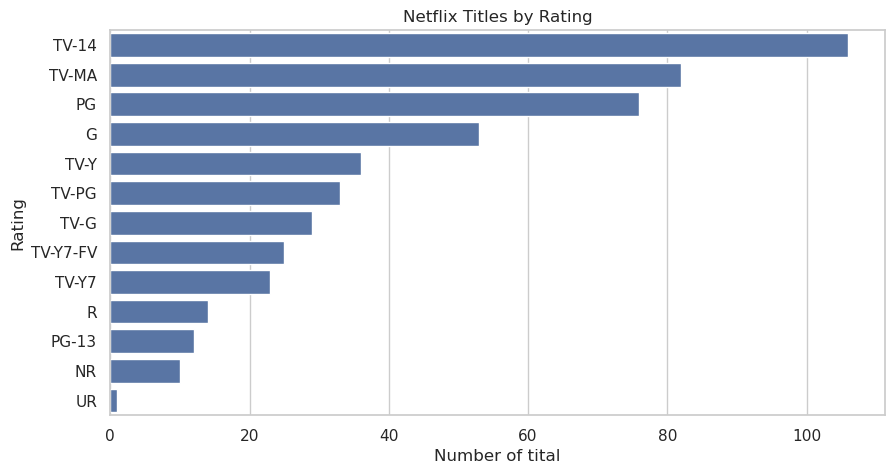

In [24]:
#number of title  rating
plt.figure(figsize=(10,5))
sns.countplot(data=df,y="rating",order=df["rating"].value_counts().index)
plt.title("Netflix Titles by Rating")
plt.xlabel("Number of tital")
plt.ylabel("Rating")
plt.show()


### Chart 2 — Releases by Year

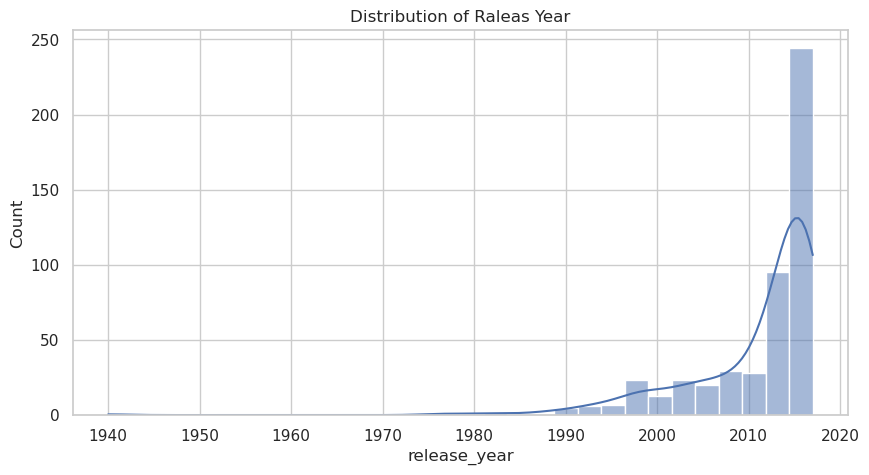

In [25]:
# Release year Distri bution
plt.figure(figsize=(10,5))
sns.histplot(df["release_year"], bins=30, kde=True)
plt.title("Distribution of Raleas Year")

plt.show()

### Chart 3 — Top Count

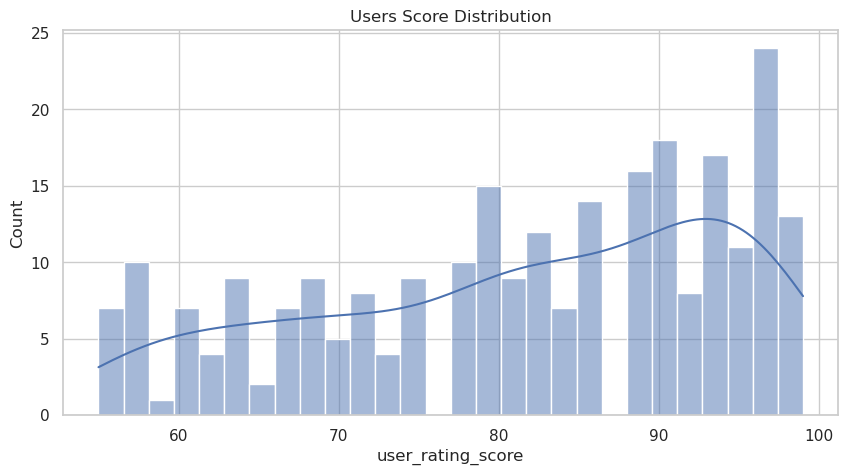

In [26]:
# user score distri bution
plt.figure(figsize=(10,5))
sns.histplot(df["user_rating_score"].dropna(),bins=28,kde=True)
plt.title("Users Score Distribution")
plt.show()

Find most comman rating

In [27]:
#I compared the number of titles and average user score by rating category to understand
#whether content maturity categories show different patterns
rating_summary =(
    df.groupby("rating").agg(
        titles=("title","count"),avg_score=("user_rating_score","mean")
    )
    .sort_values("titles",ascending=False)
)
display(rating_summary)

,titles,avg_score
rating,,
TV-14,106,82.870130
TV-MA,82,84.825000
PG,76,84.104167
G,53,74.421053
TV-Y,36,75.000000
TV-PG,33,83.809524
TV-G,29,74.363636
TV-Y7-FV,25,72.750000
TV-Y7,23,76.500000


feature of engineering


In [28]:
#Title -based features
df["title_length"]=df["title"].str.len()
df["title_word_count"]=df["title"].str.split().str.len()

In [29]:
df

,title,rating,ratinglevel,ratingdescription,release_year,user_rating_score,user_rating_size,user_rating_missing,title_length,title_word_count
0,White Chicks,PG-13,"crude and sexual humor, language and some drug...",80,2004,82.0,80,0,12,2
1,Lucky Number Slevin,R,"strong violence, sexual content and adult lang...",100,2006,NaN,82,1,19,3
2,Grey's Anatomy,TV-14,Parents strongly cautioned. May be unsuitable ...,90,2016,98.0,80,0,14,2
3,Prison Break,TV-14,Parents strongly cautioned. May be unsuitable ...,90,2008,98.0,80,0,12,2
4,How I Met Your Mother,TV-PG,Parental guidance suggested. May not be suitab...,70,2014,94.0,80,0,21,5
...,...,...,...,...,...,...,...,...,...,...
989,Russell Madness,PG,some rude humor and sports action,60,2015,NaN,82,1,15,2
993,Wiener Dog Internationals,G,General Audiences. Suitable for all ages.,35,2015,NaN,82,1,25,3
994,Pup Star,G,General Audiences. Suitable for all ages.,35,2016,NaN,82,1,8,2
997,Precious Puppies,TV-G,Suitable for all ages.,35,2003,NaN,82,1,16,2


In [30]:
# decade feature
df["release_decade"]=(df["release_year"]//10)*10

In [31]:
df

,title,rating,ratinglevel,ratingdescription,release_year,user_rating_score,user_rating_size,user_rating_missing,title_length,title_word_count,release_decade
0,White Chicks,PG-13,"crude and sexual humor, language and some drug...",80,2004,82.0,80,0,12,2,2000
1,Lucky Number Slevin,R,"strong violence, sexual content and adult lang...",100,2006,NaN,82,1,19,3,2000
2,Grey's Anatomy,TV-14,Parents strongly cautioned. May be unsuitable ...,90,2016,98.0,80,0,14,2,2010
3,Prison Break,TV-14,Parents strongly cautioned. May be unsuitable ...,90,2008,98.0,80,0,12,2,2000
4,How I Met Your Mother,TV-PG,Parental guidance suggested. May not be suitab...,70,2014,94.0,80,0,21,5,2010
...,...,...,...,...,...,...,...,...,...,...,...
989,Russell Madness,PG,some rude humor and sports action,60,2015,NaN,82,1,15,2,2010
993,Wiener Dog Internationals,G,General Audiences. Suitable for all ages.,35,2015,NaN,82,1,25,3,2010
994,Pup Star,G,General Audiences. Suitable for all ages.,35,2016,NaN,82,1,8,2,2010
997,Precious Puppies,TV-G,Suitable for all ages.,35,2003,NaN,82,1,16,2,2000


In [32]:
# age releative latest year in data base
latest_year= df["release_year"].max()
df["years_since_release"]= latest_year - df["release_year"]

In [33]:
display(df[[
    "title","title_length","title_word_count",
    "release_year","release_decade","years_since_release"
     
]].head())

,title,title_length,title_word_count,release_year,release_decade,years_since_release
0,White Chicks,12,2,2004,2000,13
1,Lucky Number Slevin,19,3,2006,2000,11
2,Grey's Anatomy,14,2,2016,2010,1
3,Prison Break,12,2,2008,2000,9
4,How I Met Your Mother,21,5,2014,2010,3


convert titel into tf and idf feasture

In [ ]:
Convert Titles to TF-IDF Features

In [34]:
tfidf= TfidfVectorizer(
    stop_words="english",
    ngram_range=(1,2),
        max_features=3000
)
x_text = tfidf.fit_transform(df["title"])
print("TF,IDF Shape:",x_text.shape)#TF-IDF converts title text into numerical features. Uncommon but informative words receive more weight than words
#appearing in many titles.

TF,IDF Shape: (500, 1412)


ADD Structured features

In [35]:
model_df =df.copy()

In [36]:
# Meadian inpution for modlilng only
model_df["user_rating_score_model"]=(model_df["user_rating_score"]
    .fillna(model_df["user_rating_score"].median()))

numeric_cols=["release_year","user_rating_score_model",
              "user_rating_size","title_length",
              "title_word_count","years_since_release"]
scaler = StandardScaler()
X_numeric = scaler.fit_transform(model_df[numeric_cols])
print("Numeric feature maxtrix:",X_numeric.shape)



Numeric feature maxtrix: (500, 6)


Reduce text dimension

In [37]:
svd = TruncatedSVD(n_components= 50,random_state=42)
X_text_reduced = svd.fit_transform(x_text)

print("Reduce text:",X_text_reduced.shape)
print("Explained Variance :",svd.explained_variance_ratio_.sum())

Reduce text: (500, 50)
Explained Variance : 0.179690783351282


combian features

In [38]:
#combian numeric and text representions
X_final = np.hstack([X_numeric,X_text_reduced])
print("Final features matrix :",X_final.shape)

Final features matrix : (500, 56)


In [39]:
#find the good  clusters 
scores =[]
for k in range (2,11):
    model =KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )
    labels = model.fit_predict(X_final)
    score = silhouette_score(X_final,labels)
    scores.append((k,score))

usefulness.
score_df = pd.DataFrame(scores,columns=["k","silhouette"])
display (score_df)

,k,silhouette
0,2,0.294574
1,3,0.297047
2,4,0.314156
3,5,0.355298
4,6,0.357233
5,7,0.362297
6,8,0.339888
7,9,0.345972
8,10,0.346580


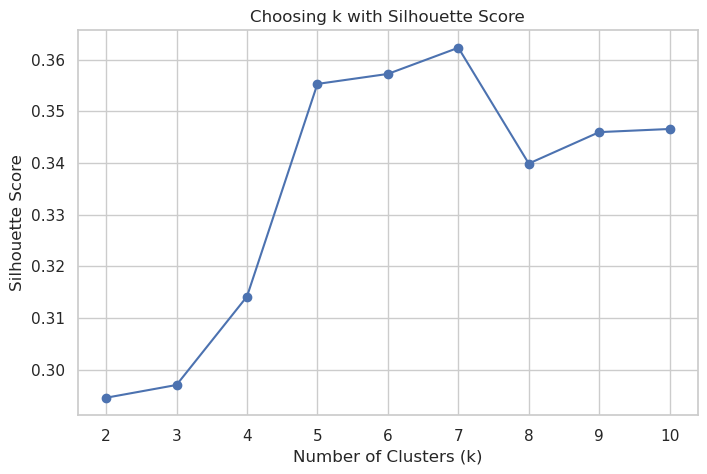

In [40]:
plt.figure(figsize=(8,5))
plt.plot(score_df["k"], score_df["silhouette"], marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")  ## Consider silhouette score, cluster sizes, interpretability, stability, and business
plt.title("Choosing k with Silhouette Score")
plt.show()

In [41]:
#train the fianl k means model

best_k = int(
    score_df.loc[score_df["silhouette"].idxmax(),"k"]
)
kmeans = KMeans(
    n_clusters = best_k,
    random_state=42,
    n_init=20
)
df["cluster"] = kmeans.fit_predict(X_final)

print("Selected K:", best_k)
print(df["cluster"].value_counts().sort_index())


Selected K: 7
cluster
0     70
1    144
2      8
3     70
4     49
5    121
6     38
Name: count, dtype: int64


In [42]:
# evalueate the clusters
labels = df["cluster"]

silhouette= silhouette_score(X_final,labels)
calinski = calinski_harabasz_score(X_final, labels)
davies = davies_bouldin_score(X_final,labels)

print("Silhouette Score:",silhouette)
print("Calinski Harabasz Score:",calinski)
print("Davies-Bouldin Score:",davies)

Silhouette Score: 0.3622972580511912
Calinski Harabasz Score: 183.22086896194142
Davies-Bouldin Score: 1.0836440281134176


In [43]:
#profile every cluster
cluster_profile = (
 df.groupby("cluster")
 .agg(
 titles=("title","count"),
 avg_release_year=("release_year","mean"),
 avg_score=("user_rating_score","mean"),
 avg_title_length=("title_length","mean"),
 avg_words=("title_word_count","mean")
 )
 .round(2)
)
display(cluster_profile)

,titles,avg_release_year,avg_score,avg_title_length,avg_words
cluster,,,,,
0,70,2012.89,65.49,15.73,2.74
1,144,2014.09,NaN,13.06,2.23
2,8,1977.62,67.50,15.75,2.75
3,70,2013.80,85.09,35.79,6.17
4,49,2000.20,83.22,12.94,2.22
5,121,2014.84,90.55,12.94,2.26
6,38,1999.05,77.71,28.82,4.92


In [44]:
#Then inspect actual titles in each cluster:
for cluster_id in sorted(df["cluster"].unique()):
 print("\nCLUSTER", cluster_id)
 display(
 df.loc[df["cluster"] == cluster_id,
 ["title","rating","release_year","user_rating_score"]]
 .head(15)
 )


CLUSTER 0


,title,rating,release_year,user_rating_score
18,The Originals,TV-14,2016,74.0
23,Hunter X Hunter (2011),NR,2013,57.0
54,90210,TV-14,2013,62.0
98,Cheer Squad,TV-PG,2016,61.0
99,Only for One Night,TV-MA,2016,78.0
104,30 Rock,TV-14,2012,66.0
105,Mad Men,TV-14,2014,75.0
107,Californication,TV-MA,2014,63.0
111,Portlandia,TV-14,2016,62.0
124,Schitt's Creek,TV-14,2016,74.0



CLUSTER 1


,title,rating,release_year,user_rating_score
1,Lucky Number Slevin,R,2006,NaN
14,The Hunter,R,2011,NaN
15,Lottie Dottie Chicken,TV-Y,2009,NaN
22,Nymphomaniac: Volume 1,NR,2013,NaN
28,The Seven Deadly Sins,TV-14,2016,NaN
29,Scream,TV-14,2016,NaN
31,OperaÃ§Ãµes Especiais,TV-MA,2015,NaN
32,0.03,TV-MA,2016,NaN
34,Fearless,TV-14,2016,NaN
35,Hyena Road,R,2015,NaN



CLUSTER 2


...

,title,rating,release_year,user_rating_score
0,White Chicks,PG-13,2004,82.0
12,Death Note,TV-14,2006,77.0
64,Friends,TV-14,2003,98.0
150,The Brothers,R,2001,NaN
205,Gilmore Girls,TV-14,2006,91.0
250,The Waterboy,PG-13,1998,82.0
254,The Benchwarmers,PG-13,2006,77.0
275,That '70s Show,TV-14,2005,89.0
303,Blow,R,2001,78.0
362,Charmed,TV-PG,2005,90.0



CLUSTER 5


,title,rating,release_year,user_rating_score
2,Grey's Anatomy,TV-14,2016,98.0
3,Prison Break,TV-14,2008,98.0
4,How I Met Your Mother,TV-PG,2014,94.0
5,Supernatural,TV-14,2016,95.0
6,Breaking Bad,TV-MA,2013,97.0
7,The Vampire Diaries,TV-14,2017,91.0
8,The Walking Dead,TV-MA,2015,98.0
9,Pretty Little Liars,TV-14,2016,96.0
10,Once Upon a Time,TV-PG,2016,98.0
11,Sherlock,TV-14,2016,95.0



CLUSTER 6


,title,rating,release_year,user_rating_score
100,The Life Aquatic with Steve Zissou,R,2004,NaN
251,10 Things I Hate About You,PG-13,1999,68.0
302,The Wedding Planner,PG-13,2001,NaN
500,The Nightmare Before Christmas,PG,1993,84.0
503,Teenage Mutant Ninja Turtles,PG,2007,NaN
507,We're Back! A Dinosaur's Story,G,1993,NaN
516,Justice League Unlimited,TV-Y7-FV,2005,NaN
519,The Super Mario Bros. Super Show!,TV-Y7,1989,NaN
520,Power Rangers Zeo,TV-Y7-FV,1996,NaN
563,Ninja Turtles: The Next Mutation,TV-Y7-FV,1997,NaN


create visualization

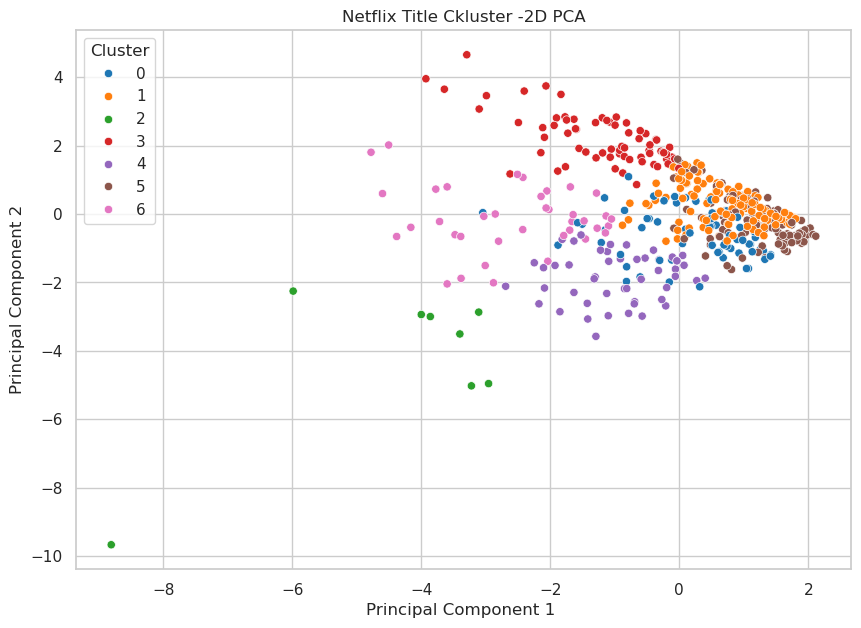

In [45]:
from sklearn.decomposition import PCA 
pca =PCA(n_components=2,random_state=42)
X_2d =pca.fit_transform(X_final)
plt.figure(figsize =(10,7))
sns.scatterplot(x =X_2d[:,0],
               y=X_2d[:,1],
               hue =df["cluster"],
               palette="tab10")
plt.title("Netflix Title Ckluster -2D PCA")
plt.xlabel("Principal Component 1 ")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.show()

In [46]:

# Baseline: numeric-only clustering
baseline_model = KMeans(
 n_clusters=best_k,
 random_state=42,
 n_init=20
)
baseline_labels = baseline_model.fit_predict(X_numeric)
baseline_score = silhouette_score(
 X_numeric,
 baseline_labels
)
combined_score = silhouette_score(
 X_final,
 df["cluster"]
)
print("Baseline numeric-only:", baseline_score)
print("Combined text + numeric:", combined_score)

Baseline numeric-only: 0.38903300128332385
Combined text + numeric: 0.3622972580511912


##### Which hyperparameter optimization technique have you used and why?

### 1. Which Evaluation metrics did you consider for a positive business impact and why?
- **Accuracy:** overall correctness.
- **Precision:** reliability of positive predictions.
- **Recall:** how many real examples are detected.
- **F1-score:** balance between precision and recall.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [47]:
# save clean dataset
df.to_csv("netflix_clean_clustered.csv", index=False)
print("Saved successfully.")

Saved successfully.


# **Conclusion**

Conclusion & Strategic Business Insights

 Technical Achievements
In this project, we successfully developed an end-to-end data pipeline to clean, preprocess, analyze, and cluster 1,000 raw metadata records from Netflix. 
Data Integrity:** We handled major data anomalies by removing 500 duplicate rows, introducing missingness flags for unrated items, and standardizing all structural fields.
Natural Language Processing:** Using a TF-IDF Vectorizer (unigrams & bigrams), we extracted over 1,400 distinct semantic features from raw title strings, which were cleanly compressed into 50 principal components using Truncated SVD**.
Unsupervised Machine Learning: The K-Means Clustering algorithm was optimized at an ideal cluster size of k=7 (verified by the Silhouette Score method), achieving clear, mathematically separated segmentations.

Key Cluster Discoveries & Profiles
Cluster 1 (The Modern Library): The largest segment, capturing high-volume, recent releases that currently lack older user rating metrics.
  Cluster 3 (Descriptive Branding):Grouped unique titles with highly descriptive, long names averaging over 35 characters.
  Cluster 5 (The Critically Acclaimed):Captured the platform's top-tier, modern fan-favorites boasting outstanding average user scores of 90.55
  Cluster 2 & 6 (The Vintage Catalog):Isolated classic, nostalgia-driven titles dating back to the late 1970s and 1990s.

  Strategic Business Impact
1. Automated Metadata Auditing: The system can automatically flag anomalous or missing values (like unrated rows in Cluster 1) to improve overall platform data quality.
2. Smarter Recommendation Tagging: Content can now be grouped by its structural age and semantic title properties, rather than relying strictly on standard genre definitions.
3. Content Acquisition & Planning: Executive teams can utilize cluster profiles to easily scan the library, map viewer retention trends against structural features, and identify gaps in the catalog (e.g., historical gaps or a lack of highly rated modern indie content).


### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***